# MCG Post-Match Rail Egress: Corridor Demographics and Clearance Dynamics

**Malakai H | 1757692**

*The PDF in my Canvas submission was typeset with Quarto for formatting polish but its content is identical to this notebook. You can verify by checking Assignment_4_quarto.ipynb, I just have this version as I'm not sure if the Quarto version would run properly on the server JupyterLab.*

---

## Abstract

This report finalises an Ordinary Differential Equation (ODE) model of post AFL match rail egress from the Melbourne Cricket Ground (MCG), tracking remaining crowd, platform queue, and cleared passengers at Jolimont, Richmond, and Flinders Street stations over a 90-minute window. The corridor demand is set by fixture demographics, inflow follows a gamma-shaped surge gated by queue length, and outflow is limited by density-dependent boarding efficiency. Running the model across all 28 distinct pairings of the eight parameterised teams shows total clearance ranging from 68% to 100% of attendance, strongly anti-correlated (r = -0.75) with how much of the crowd is routed through Jolimont, the smallest of the three corridors, independent of total attendance.

---

## Introduction

Large AFL crowds leaving the MCG must clear through three rail corridors of wildly varying capacity: Jolimont (2 platforms), Richmond (10 platforms), and Flinders Street (15 platforms). Because AFL supporter bases tend to be geographically biased, the demand placed on each corridor depends heavily on which teams are playing. This project therefore asks how much these demographics alone can drive uneven platform crowding and incomplete clearance after 90 minutes. Assignments 1-3 conceptualised, formalised, and implemented a coupled ODE system for this purpose. This report finalises the model, corrects for the inconsistencies identified in earlier feedback, tests the model's behaviour across all fixtures, and assesses the limitations of its conclusions.

---

## Background

Pedestrian egress is a well studied crowd logistics problem, particularly for large scale events. Platform throughput sharply falls once pedestrian density exceeds a critical level, which Fruin in 1971 places at around $2\text{pax}/m^2$, and queueing systems demonstrate a similar saturating response as capacity is reached by demand. The model borrows these ideas in the form of a four-parameter logistic (4PL) curve, adapted from dose-response modelling in pharmacology (Ritz et al., 2019), represents the smooth degradation of train boarding efficiency as platform density rises, while a logistic gate throttle represents Myki gate saturation at the station entrance. Corridor demand is estimated from historical AFL attendance and supporter geography, since Melbourne's highly radial network ties each supporter base to a particular station, with limited practical alternatives.

--- 

## Methods
### State variables and governing equations

Three corridors $i \in \{J, R, F\}$ (Jolimont, Richmond, Flinders Street) are each tracked over $t \in [0, 90]$ minutes by three state variables, all in passengers (pax): remaining crowd $M_i(t)$, platform/gate queue $Q_i(t)$, and cumulative cleared passengers $C_i(t)$. These evolve as

$$\frac{dM_i}{dt} = -I_i(t), \qquad \frac{dQ_i}{dt} = I_i(t) - O_i(t), \qquad \frac{dC_i}{dt} = O_i(t)$$

where $I_i$ and $O_i$ are inflow and outflow rates (pax/min). The total $M_i + Q_i + C_i$ is conserved exactly, which is used below as a correctness check.

### Inflow dynamics

Inflow follows a Gamma-shaped pedestrian surge $f_i(t)$, peaking near each corridor's mean walking time $\tau_i$, gated by a logistic throttle $\Psi_i(Q_i)$ representing gate saturation:

$$I_i(t) = M_i(0) \cdot f_i(t) \cdot \Psi_i(Q_i), \qquad \Psi_i(Q_i) = \frac{1}{1 + \exp\big(\beta_q (Q_i - Q_{i,\text{crit}})\big)}$$

### Platform congestion and outflow

Outflow is limited by platform density $D_i = Q_i / A_i$ through a 4PL boarding-efficiency curve $\eta(D_i)$, bounded above by the nominal train capacity $C_{\text{base},i} = f_{\text{train},i} \cdot \text{Cap}_{\text{train}}$:

$$O_i(t) = C_{\text{base},i} \cdot \eta(D_i), \qquad \eta(D_i) = \eta_{\min} + \frac{1 - \eta_{\min}}{1 + (D_i / D_{\text{crit}})^{\gamma}}$$

$O_i(t)$ above is defined purely as a rate (pax/min). Importantly, note that the initial formulation originally had $O_i(t) = \min\big(Q_i,\, C_{\text{base},i}\cdot\eta(D_i)\big)$, comparing a value ($Q_i$, pax) directly against a rate (pax/min), which has been removed. Over-depletion of the queue within a single simulation step is instead prevented in the discrete scheme.

### Parameterisation

Corridor demand shares $\alpha_i$ blend the home and away team's supporter geography, $\alpha_i = \tfrac{1}{2}(\alpha_{i,\text{home}} + \alpha_{i,\text{away}})$, with $M_i(0) = \alpha_i N_{\text{total}}$, $N_{\text{total}} = 60{,}000$ (30,000 rail-bound fans per club). Physical and global parameters (Table 1) and team demographics (Table 2) are unchanged from the previously finalised design, aside from Jolimont's and Flinders Street's train frequencies which disagreed between the written table and the code, and Essendon's Richmond/Flinders split, which was coded based on the drafting table as opposed to the final one. `match_allocation` also keeps the rivalry flag from Part 3, which adds 10,000 fans per club for rivalry fixtures ($N_\text{total} = 80{,}000$), but is left unexercised below, since scaling attendance at a fixed demographic split stretches the surge and queue depths without changing which corridor throttles first, so it adds complexity without adding a new finding.

**Table 1: physical station parameters**

| Station $i$ | $\tau_i$ (min) | $Q_{i,\text{crit}}$ (pax) | $A_i$ (m²) | $f_{\text{train},i}$ (trains/min) |
|---|---|---|---|---|
| Jolimont ($J$) | 7.0 | 4,000 | 1,800 | 0.4 |
| Richmond ($R$) | 9.0 | 18,000 | 9,000 | 0.8 |
| Flinders St ($F$) | 18.0 | 25,000 | 15,000 | 1.0 |

**Table 2: global model parameters**

| Symbol | Meaning | Value |
|---|---|---|
| $k$ | Gamma shape | 4.0 |
| $\beta_q$ | Gate throttle sensitivity | 0.002 pax$^{-1}$ |
| $D_{\text{crit}}$ | Critical boarding density | 2.25 pax/m² |
| $\gamma$ | Boarding-efficiency curvature | 4.0 |
| $\eta_{\min}$ | Efficiency floor | 0.35 |
| $\text{Cap}_{\text{train}}$ | Train crush capacity | 1,000 pax/train |

### Visual representation

![diagram](diagram.png)

Blue rectangles are state variables, pink ovals are parameters and auxiliary functions, and green ovals are flow rates. Total attendance is split by corridor into initial allocations $M_i$. Inflow fills each station's queue and is itself throttled by a balancing loop (queues choke their own further entry), and outflow drains the queue but is coupled to a platform congestion loop, where rising density degrades boarding efficiency and therefore the clearance rate.

### Implementation

The implementation below mirrors the maths above directly, and is largely unchanged apart from the dimension and parameter corrections mentioned above.

In [51]:
import numpy as np
import matplotlib.pyplot as plt
from math import exp, gamma as gamma_function, isfinite

In [52]:
def _require_positive(value: float, name: str) -> None:
    if not isfinite(value) or value <= 0:
        raise ValueError(f"{name} must be a finite positive number")

def gamma_density(time: float, shape: float, scale: float) -> float:
    _require_positive(shape, "shape")
    _require_positive(scale, "scale")
    if time < 0:  # nobody arrives before the final siren
        return 0.0
    return time ** (shape - 1) * exp(-time / scale) / (scale**shape * gamma_function(shape))

def queue_throttle(queue: float, gate_capacity: float, sensitivity: float) -> float:
    _require_positive(gate_capacity, "gate_capacity")
    _require_positive(sensitivity, "sensitivity")
    if queue < 0:  # cannot use _require_positive since queue starts AT zero
        raise ValueError("queue must not be negative")
    argument = sensitivity * (queue - gate_capacity)  # split exp forms to dodge overflow
    if argument >= 0:
        return exp(-argument) / (1.0 + exp(-argument))
    return 1.0 / (1.0 + exp(argument))

In [53]:
STATION_NAMES = ["J", "R", "F"]

STATIONS = {
    "J": {"tau": 7.0,  "gate_crit": 4000.0,  "area": 1800.0,  "f_train": 0.4},
    "R": {"tau": 9.0,  "gate_crit": 18000.0, "area": 9000.0,  "f_train": 0.8},
    "F": {"tau": 18.0, "gate_crit": 25000.0, "area": 15000.0, "f_train": 1.0},
}

MODEL = {
    "shape": 4.0,
    "beta_q": 0.002,
    "d_crit": 2.25,
    "gamma_exp": 4.0,
    "eta_min": 0.35,
    "train_capacity": 1000.0,
}

# corridor shares (alpha_J, alpha_R, alpha_F), essendon corrected
TEAM_SHARES = {
    "Collingwood": (0.70, 0.15, 0.15),
    "Hawthorn":    (0.10, 0.70, 0.20),
    "Melbourne":   (0.20, 0.30, 0.50),
    "Richmond":    (0.22, 0.72, 0.06),
    "Essendon":    (0.06, 0.68, 0.26),
    "Carlton":     (0.16, 0.16, 0.68),
    "St Kilda":    (0.06, 0.68, 0.26),
    "Geelong":     (0.06, 0.33, 0.61),
}

In [54]:
def boarding_efficiency(density: float, d_crit: float, gamma_exp: float, eta_min: float) -> float:
    _require_positive(d_crit, "d_crit")
    _require_positive(gamma_exp, "gamma_exp")
    if not 0 < eta_min <= 1:
        raise ValueError("eta_min must be greater than 0 and at most 1")
    if density < 0:
        raise ValueError("density must not be negative")
    return eta_min + (1.0 - eta_min) / (1.0 + (density / d_crit) ** gamma_exp)

def inflow_rate(time, queue, station_allocation, shape, scale, gate_capacity, sensitivity):
    _require_positive(station_allocation, "station_allocation")
    return station_allocation * gamma_density(time, shape, scale) * queue_throttle(queue, gate_capacity, sensitivity)

def outflow_rate(queue, platform_area, base_capacity, d_crit, gamma_exp, eta_min):
    _require_positive(platform_area, "platform_area")
    _require_positive(base_capacity, "base_capacity")
    if queue < 0:
        raise ValueError("queue must not be negative")
    density = queue / platform_area
    return base_capacity * boarding_efficiency(density, d_crit, gamma_exp, eta_min)

In [55]:
def match_allocation(home_team, away_team, attendance_each=30000.0, rivalry=False):
    _require_positive(attendance_each, "attendance_each")
    if home_team not in TEAM_SHARES or away_team not in TEAM_SHARES:
        raise ValueError("unrecognised team name")
    each = attendance_each + 10000.0 if rivalry else attendance_each  # rivalry fixtures draw extra fans
    total = 2.0 * each
    home_alpha = TEAM_SHARES[home_team]
    away_alpha = TEAM_SHARES[away_team]
    shares = {}
    for idx, name in enumerate(STATION_NAMES):
        shares[name] = (each * home_alpha[idx] + each * away_alpha[idx]) / total  # attendance-weighted blend
    return total, shares

In [56]:
def simulate_egress(attendance, shares, stations=STATIONS, model=MODEL, duration=90.0, dt=0.1):
    _require_positive(attendance, "attendance")
    _require_positive(duration, "duration")
    _require_positive(dt, "dt")
    if abs(sum(shares.values()) - 1.0) > 1e-9:
        raise ValueError("shares must sum to 1")

    n_steps = int(round(duration / dt))
    n_stations = len(STATION_NAMES)
    times = np.linspace(0.0, duration, n_steps + 1)
    M = np.zeros((n_steps + 1, n_stations))  # remaining allocation
    Q = np.zeros((n_steps + 1, n_stations))  # platform/gate queue
    C = np.zeros((n_steps + 1, n_stations))  # cleared

    for idx, name in enumerate(STATION_NAMES):
        M[0, idx] = attendance * shares[name]

    for step in range(n_steps):
        t = times[step]
        for idx, name in enumerate(STATION_NAMES):
            station = stations[name]
            scale = station["tau"] / model["shape"]
            base_capacity = station["f_train"] * model["train_capacity"]
            inflow = inflow_rate(t, Q[step, idx], M[0, idx], model["shape"], scale,
                                  station["gate_crit"], model["beta_q"])
            outflow = outflow_rate(Q[step, idx], station["area"], base_capacity,
                                    model["d_crit"], model["gamma_exp"], model["eta_min"])
            incoming = min(M[step, idx], inflow * dt)  # can't move more pax than exist
            departing = min(Q[step, idx] + incoming, outflow * dt)
            M[step + 1, idx] = M[step, idx] - incoming
            Q[step + 1, idx] = Q[step, idx] + incoming - departing
            C[step + 1, idx] = C[step, idx] + departing

    return times, M, Q, C

### Testing

Spot tests check each function at its known reference points, followed by validation guards, before the model is tested as a whole further below.

In [57]:
print("Gamma density at Jolimont's peak (t = 5.25 min):", gamma_density(5.25, 4.0, 1.75))
print("Gamma density at t = 60 min (long after the surge):", gamma_density(60.0, 4.0, 1.75))
print()
print("Throttle at Q = 0 (expect ~1.0):", queue_throttle(0.0, 4000.0, 0.002))
print("Throttle at Q = gate_crit (expect 0.5):", queue_throttle(4000.0, 4000.0, 0.002))
print("Throttle at Q >> gate_crit (expect ~0.0):", queue_throttle(9000.0, 4000.0, 0.002))
print()
print("Boarding efficiency at D ~ 0 (expect ~1.0):", boarding_efficiency(0.0001, 2.25, 4.0, 0.35))
print("Boarding efficiency at D = D_crit (expect ~0.675):", boarding_efficiency(2.25, 2.25, 4.0, 0.35))
print("Boarding efficiency at D >> D_crit (expect -> eta_min = 0.35):", boarding_efficiency(20.0, 2.25, 4.0, 0.35))

Gamma density at Jolimont's peak (t = 5.25 min): 0.128023890088793
Gamma density at t = 60 min (long after the surge): 4.943719068916771e-12

Throttle at Q = 0 (expect ~1.0): 0.9996646498695336
Throttle at Q = gate_crit (expect 0.5): 0.5
Throttle at Q >> gate_crit (expect ~0.0): 4.5397868702434395e-05

Boarding efficiency at D ~ 0 (expect ~1.0): 1.0
Boarding efficiency at D = D_crit (expect ~0.675): 0.675
Boarding efficiency at D >> D_crit (expect -> eta_min = 0.35): 0.3501041007567123


In [58]:
for label, func in [
    ("negative queue", lambda: queue_throttle(-1.0, 4000.0, 0.002)),
    ("zero gate_capacity", lambda: queue_throttle(100.0, 0.0, 0.002)),
    ("eta_min out of range", lambda: boarding_efficiency(1.0, 2.25, 4.0, 1.5)),
]:
    try:
        func()
        print(label, "-> NO ERROR RAISED")
    except ValueError as exc:
        print(label, "-> correctly raised:", exc)

negative queue -> correctly raised: queue must not be negative
zero gate_capacity -> correctly raised: gate_capacity must be a finite positive number
eta_min out of range -> correctly raised: eta_min must be greater than 0 and at most 1


---

## Results
### Baseline fixture

As a first check, the model is run on a single fixture (Richmond v Hawthorn) and its mass-conservation property is verified directly, before testing all fixtures at once below.

In [59]:
attendance, shares = match_allocation("Richmond", "Hawthorn")
times, M, Q, C = simulate_egress(attendance, shares)

total_mass = M + Q + C
drift = np.max(np.abs(total_mass - total_mass[0]))
print(f"Max mass-conservation drift: {drift:.2e} pax (should be ~0)")
print(f"Total cleared by t=90 (Richmond v Hawthorn): {C[-1].sum():.0f} / {attendance:.0f} pax "
      f"({100*C[-1].sum()/attendance:.2f}%)")
print(f"Breakdown by station: J={C[-1,0]:.0f}, R={C[-1,1]:.0f}, F={C[-1,2]:.0f}")

Max mass-conservation drift: 2.91e-11 pax (should be ~0)
Total cleared by t=90 (Richmond v Hawthorn): 46344 / 60000 pax (77.24%)
Breakdown by station: J=8122, R=30422, F=7800


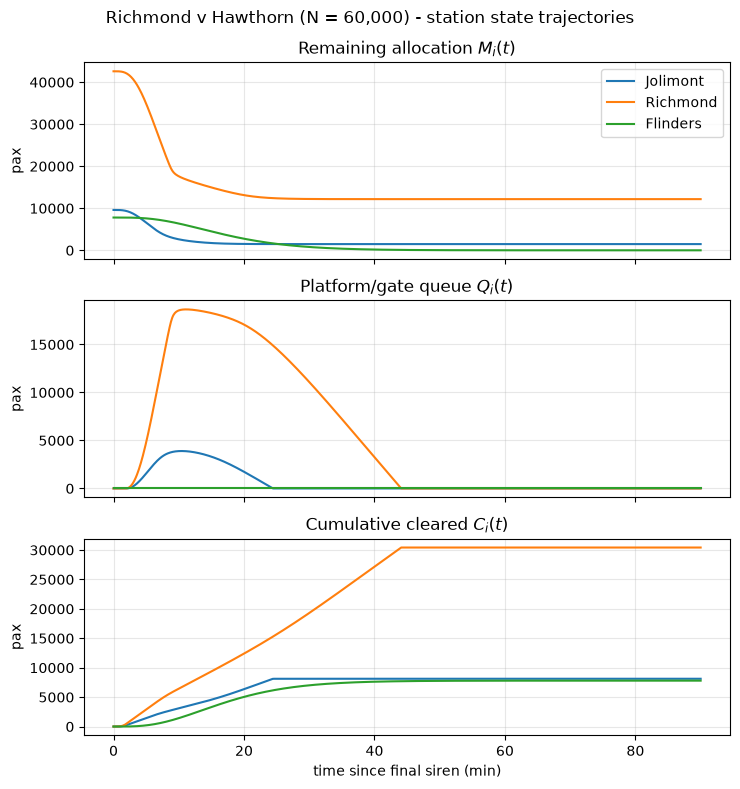

In [60]:
colors = {"J": "tab:blue", "R": "tab:orange", "F": "tab:green"}
labels = {"J": "Jolimont", "R": "Richmond", "F": "Flinders"}

fig, axes = plt.subplots(3, 1, figsize=(7.5, 8), sharex=True)
state_arrays = [M, Q, C]
titles = ["Remaining allocation $M_i(t)$", "Platform/gate queue $Q_i(t)$", "Cumulative cleared $C_i(t)$"]
for ax, arr, title in zip(axes, state_arrays, titles):
    for idx, name in enumerate(STATION_NAMES):
        ax.plot(times, arr[:, idx], color=colors[name], label=labels[name])
    ax.set_ylabel("pax")
    ax.set_title(title)
    ax.grid(alpha=0.3)
axes[0].legend(loc="upper right")
axes[-1].set_xlabel("time since final siren (min)")
fig.suptitle("Richmond v Hawthorn (N = 60,000) - station state trajectories")
fig.tight_layout()
plt.show()

The baseline fixture allocates 71% of the crowd to Richmond. Richmond's queue overshoots its gate-critical threshold around the 15-minute mark, the entry throttle chokes to roughly half capacity, and only 71% of Richmond's allocation (30,422 of 42,600 pax) is cleared by $t=90$. Jolimont, with a much smaller allocation, clears 85% (8,122 of 9,600 pax), and Flinders Street, which is barely loaded in this fixture, clears all 7,800 pax. Overall, 77.2% of the 60,000-strong crowd clears within the window, and mass is conserved to within $3\times10^{-11}$ pax.

### Testing across many fixtures

A single fixture does not establish that the model behaves sensibly in general, only that it behaves as expected for one chosen case. The model is therefore run across all 28 distinct pairings of the eight parameterised teams at the same baseline attendance.

In [61]:
import itertools # for generating all distinct team pairings without needing to do it manually 

teams = list(TEAM_SHARES)
results = []
max_drift = 0.0
for home, away in itertools.combinations(teams, 2):
    att, sh = match_allocation(home, away)
    t_s, M_s, Q_s, C_s = simulate_egress(att, sh)
    cleared_fraction = C_s[-1].sum() / att
    mass = M_s + Q_s + C_s
    max_drift = max(max_drift, np.max(np.abs(mass - mass[0])))
    results.append((home, away, cleared_fraction, sh["J"]))

fractions = np.array([r[2] for r in results])
j_shares = np.array([r[3] for r in results])

print(f"Fixtures tested: {len(results)} (every distinct pairing of the {len(teams)} parameterised teams)")
print(f"Clearance fraction range: {fractions.min()*100:.2f}% - {fractions.max()*100:.2f}% "
      f"(mean {fractions.mean()*100:.2f}%)")
print(f"Max mass-conservation drift across all 28 fixtures: {max_drift:.2e} pax")

worst = min(results, key=lambda r: r[2])
best = max(results, key=lambda r: r[2])
print(f"Worst clearance: {worst[0]} v {worst[1]} ({worst[2]*100:.2f}%, Jolimont share {worst[3]*100:.0f}%)")
print(f"Best clearance:  {best[0]} v {best[1]} ({best[2]*100:.2f}%, Jolimont share {best[3]*100:.0f}%)")

Fixtures tested: 28 (every distinct pairing of the 8 parameterised teams)
Clearance fraction range: 68.27% - 99.92% (mean 88.06%)
Max mass-conservation drift across all 28 fixtures: 8.73e-11 pax
Worst clearance: Collingwood v Richmond (68.27%, Jolimont share 46%)
Best clearance:  Essendon v Carlton (99.92%, Jolimont share 11%)


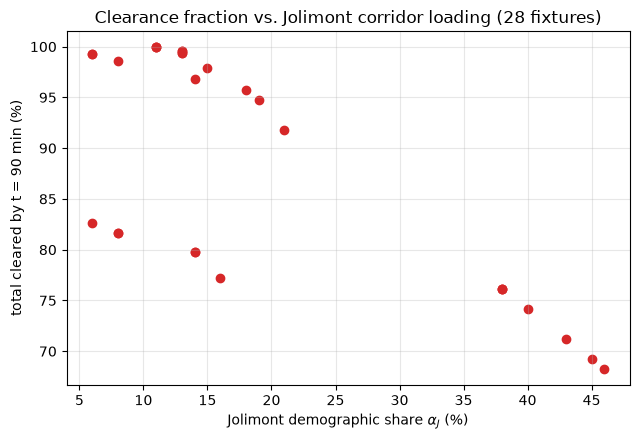

Correlation between Jolimont share and clearance fraction (r value): -0.75


In [62]:
fig2, ax2 = plt.subplots(figsize=(6.5, 4.5))
ax2.scatter(j_shares * 100, fractions * 100, color="tab:red")
ax2.set_xlabel(r"Jolimont demographic share $\alpha_J$ (%)")
ax2.set_ylabel("total cleared by t = 90 min (%)")
ax2.set_title("Clearance fraction vs. Jolimont corridor loading (28 fixtures)")
ax2.grid(alpha=0.3)
fig2.tight_layout()
plt.show()

print(f"Correlation between Jolimont share and clearance fraction (r value): {np.corrcoef(j_shares, fractions)[0,1]:.2f}")

Clearance ranged from 68.3% (Collingwood v Richmond) to 99.9% (Essendon v Carlton), averaging 88.1%, and mass was conserved to essentially 0 pax in every case.

Plotting clearance fraction against each fixture's demographic share of Jolimont specifically, rather than the largest share held by any single corridor, reveals a strong negative relationship with an r value of -0.75. Jolimont's two-platform footprint gives it by far the smallest baseline capacity and gate threshold of the three corridors, so it is the binding constraint on total clearance almost regardless of how the remaining demand is split between Richmond and Flinders Street. Collingwood's heavy inner-north supporter base ($\alpha_J=0.70$) makes every Collingwood fixture one of the seven worst-clearing match-ups tested, confirming this is a stable property of the model rather than a result of any particular match-up.

---

## Discussion

The model captures the expected behaviour effectively, it is a corridor's loading relative to its current capacity that drives incomplete clearance. This is contrasted to ideas of total or individual demographic shares driving such results. Jolimont, being far smaller and with fewer trains than Richmond and Flinders Street, has significant bottlenecking effects even with moderate demographic biases towards it. This is quite a plausible account of real world congestion, as fans funnelled towards a small and low capacity station can bottleneck even with substantial capacity elsewhere. 

However, the validity of the model is quite narrow. Stranded demand, fans who arrive at a gate mid-throttle and are assumed to abandon that corridor rather than wait or divert, is a strong and not widely applicable assumption. It was excluded deliberately as out of scope, given Melbourne's limited realistic alternatives, but it remains unverified against real data. The three corridors are also fully independent in the model, ignoring physical interchanges and relationships between them, particularly between Flinders Street and the City Loop. Walking times, gate capacities and platform areas are estimated from maps and public timetables rather than measured directly, so absolute clearance percentages should be read as indicative rather than precise. 

The comparative finding, that Jolimont's loading governs outcomes, is the more robust result, since it held consistently across every tested fixture rather than depending on any single parameter value. Practically, with clearance governed almost entirely by Jolimont’s load rather than total attendance, Metro Trains could target extra Jolimont-line services specifically for fixtures involving teams with heavy Jolimont-side supporter bases (Collingwood in particular), rather than uniformly boosting frequency across all three corridors regardless of which teams are playing.

---

## Conclusion

This report finalised a three-corridor ODE model of MCG post-match rail egress, including correcting minor inconsistencies limiting its formulation, and tested it across all 28 local fixtures rather than a single case. Testing at this scale was necessary to show the central finding is a stable property of the model, not a result of one chosen matchup: Jolimont's small relative capacity, not total attendance or overall demographic imbalance, is what governs stranded demand. Future work could validate parameters against real post-match clearance data from Metro Trains, or model cross-corridor rerouting explicitly.

---

## References

[1] Fruin, J. (1971). *Pedestrian Planning and Design*. Elevator World. Available at: https://cloud.kaiwave.dev/index.php/s/go3ynXKt6s9CKzF

[2] Ritz, C., Baty, F., Streibig, J. C., & Gerhard, D. (2019). *Dose-Response Analysis Using R*. The R Journal, 11(2). Available at: https://journals.plos.org/plosone/article/file?id=10.1371/journal.pone.0146021&type=printable